# 30_ml: SVR dự báo SOH chu kỳ kế tiếp

**Người làm:** Minh Vũ · **Review:** Khải Hưng · **Kế hoạch:** `docs/Go.md` GĐ5c, WBS C6.2–C6.5 · **Trả lời:** RQ4

> Đặc trưng sạc và trở kháng dự báo SOH chu kỳ kế tiếp tốt đến đâu, và đặc trưng nào quan trọng nhất?

Toàn bộ code nằm trong **`src/svr_model.py`**, chia thành các class. Notebook này chỉ gọi từng class theo thứ tự và hiển thị kết quả trung gian:

| Class | Việc làm | Bước SVR (Chap 6, tr. 33) |
|---|---|---|
| `SVRConfig` | Gom mọi tham số tự chọn ở một chỗ | – |
| `FeatureBuilder` | Tạo đặc trưng, kiểm tra không rò rỉ dữ liệu | Bước 3 |
| `RecursiveForecaster` | Dự báo cuốn chiếu nhiều bước (E2) | Bước 5 |
| `SVRTuner` | Chọn C, ε, γ bằng GroupKFold theo pin + quy tắc 1-SE | Bước 4 |
| `SVRForecaster` | Train model cuối, dự báo E1/E2, tạo file dự báo | Bước 5 |
| `ImportanceAnalyzer` | Permutation importance (RQ4) | – |
| `SVRPlotter` | Vẽ hình | Bước 7–8 |
| `SVRExperiment` | Gọi các class trên theo đúng thứ tự | – |

**Đầu ra:** `reports/predictions/svr.csv`, `reports/figures/svr_tuning_heatmap.png`, `reports/figures/svr_forecasts.png`, `reports/figures/svr_permutation_importance.png`.

Chạy bằng Restart & Run All. Có thể chạy cả quy trình không cần notebook: `python src/svr_model.py`.

## Bước 1. Import và khởi tạo

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "protocol.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from svr_model import SVRConfig, SVRExperiment

pd.set_option("display.width", 140)
exp = SVRExperiment(SVRConfig())     # tạo sẵn tất cả các class, dùng chung một cấu hình

## Bước 2. Đọc dữ liệu và chia train/test (dùng chung cả nhóm)

`load_split()` trong `src/protocol.py` lấy các pin tier A, bỏ dòng `cap_outlier` và `break_in`, rồi chia **theo pin**:
- **train:** B0005, B0006, B0018, B0033, B0045, B0046, B0048, B0056
- **test:** B0007 (24°C/2 A), B0034 (24°C/4 A), B0047 (4°C/1 A), B0055 (4°C/2 A)
- `is_eval` đánh dấu 40% chu kỳ cuối của mỗi pin test: chỉ dự báo các dòng này.

*Vì sao chia theo pin, không chia ngẫu nhiên theo chu kỳ:* hai chu kỳ liền nhau của một pin gần như giống hệt nhau. Chia ngẫu nhiên thì model "nhìn trộm" được đáp án, R² lên khoảng 0,99 nhưng là ảo.

In [2]:
train, test = exp.load_data()          # gọi luôn FeatureBuilder.check_no_leakage() và training_matrix()
assert (len(train), len(test), test.is_eval.sum()) == (947, 528, 213)
assert not set(train.battery_id) & set(test.battery_id)     # không pin nào nằm ở cả hai tập

pd.concat([train.assign(set="train"), test.assign(set="test")]).groupby(["set", "battery_id"]).agg(
    n=("soh", "size"), ambient_C=("ambient_C", "first"), I_level_A=("I_level_A", "first"),
    cutoff_V=("discharge_cutoff_V", "first"), soh_min=("soh", "min"))

n  ambient_C  I_level_A  cutoff_V   soh_min
set   battery_id                                               
test  B0007       167       24.0        2.0       2.2  0.746373
      B0034       194       24.0        4.0       2.2  0.798767
      B0047        68        4.0        1.0       2.5  0.744429
      B0055        99        4.0        2.0       2.5  0.790655
train B0005       167       24.0        2.0       2.7  0.696675
      B0006       166       24.0        2.0       2.5  0.575568
      B0018       132       24.0        2.0       2.5  0.732746
      B0033       178       24.0        4.0       2.0  0.783107
      B0045        67        4.0        1.0       2.0  0.724013
      B0046        68        4.0        1.0       2.2  0.776649
      B0048        68        4.0        1.0       2.7  0.772769
      B0056       101        4.0        2.0       2.7  0.818312

## Bước 3. Đặc trưng (`FeatureBuilder`)

Với lần xả ở chu kỳ *t*, model chỉ được dùng thông tin đã biết **trước** lần xả đó (Go.md 4.6):

| Đặc trưng | Ý nghĩa | Vì sao được phép |
|---|---|---|
| `soh_lag1` … `soh_lag5`, `soh_roll5` | SOH của 5 chu kỳ trước và trung bình | giá trị quá khứ |
| `chg_cc_time_s` | thời gian pha CC của lần sạc ngay trước (F7) | đo trước khi xả |
| `Re_ohm`, `Rct_ohm` | trở kháng đo lần gần nhất **trước** chu kỳ *t* | đã ghép ngược thời gian ở bước tiền xử lý |
| `T_max_prev_C` | nhiệt độ cao nhất của lần xả **trước** | giá trị của *t−1* |
| `log_rest_h` | log(1 + thời gian nghỉ), vì biến này lệch phải rất mạnh (F5) | biết khi bắt đầu xả |
| `is_4C`, `I_level_A`, `cutoff_V` | điều kiện vận hành | cố định theo thiết kế |

**Bị cấm** (rò rỉ cùng chu kỳ): `capacity_*`, `energy_Wh`, `duration_s`, `t_to_cutoff_s`, `T_max_C` và `V_min` của chính chu kỳ *t*. `check_no_leakage()` đã kiểm tra ở bước 2.

**Chuẩn hóa:** SVR đo khoảng cách giữa các điểm, nên đặc trưng tính bằng giây và bằng ohm phải đưa về cùng thang đo. `StandardScaler` nằm **trong Pipeline**, nên ở mỗi fold nó chỉ học mean/SD từ phần train. 57 giá trị Re/Rct bị thiếu (19 chu kỳ đầu của B0005–B0007, trước lần đo EIS đầu tiên) được điền bằng median, cũng trong Pipeline.

In [3]:
print(f"số đặc trưng: {len(exp.builder.feature_names)}   dòng train: {len(exp.X_tr)} / {len(train)}"
      " (mỗi pin bỏ 5 chu kỳ đầu vì chưa đủ lag)")
exp.X_tr.describe().T.round(4)

số đặc trưng: 14   dòng train: 907 / 947 (mỗi pin bỏ 5 chu kỳ đầu vì chưa đủ lag)


,count,mean,std,min,25%,50%,75%,max
soh_lag1,907.0,0.8406,0.0921,0.5756,0.7786,0.8458,0.9123,1.0014
soh_lag2,907.0,0.8425,0.0924,0.5756,0.7804,0.8477,0.9165,1.0014
soh_lag3,907.0,0.8445,0.0927,0.5756,0.7828,0.8493,0.9196,1.0014
soh_lag4,907.0,0.8466,0.0931,0.5756,0.7835,0.8518,0.9224,1.0014
soh_lag5,907.0,0.8489,0.0937,0.5858,0.7863,0.8559,0.9249,1.0413
soh_roll5,907.0,0.8446,0.0921,0.5807,0.7828,0.8518,0.9179,0.9985
chg_cc_time_s,907.0,1668.6340,917.8181,0.0000,866.7890,1743.4690,2356.9610,3547.0000
Re_ohm,879.0,0.0747,0.0154,0.0436,0.0627,0.0749,0.0825,0.1383
Rct_ohm,879.0,0.1296,0.0541,0.0678,0.0872,0.1025,0.1853,0.2524
T_max_prev_C,907.0,34.0774,14.7624,10.1963,15.1739,38.5209,41.2005,61.1372


## Bước 4. Chọn tham số (`SVRTuner`)

SVR tìm một hàm sao cho phần lớn điểm train nằm trong một "ống" rộng **ε** quanh hàm đó (Chap 6, tr. 31):
- sai số nhỏ hơn ε: coi như đúng; lớn hơn ε: bị phạt với trọng số **C** (C lớn thì bám sát dữ liệu, dễ học vẹt);
- **γ**: độ "cục bộ" của kernel RBF. γ nhỏ cho hàm mượt, gần tuyến tính; γ lớn cho hàm uốn lượn.

**4a. Grid search.** `GroupKFold(4)` theo pin trên tập train: mỗi fold giữ lại nguyên 2 pin train để kiểm tra, giống cách tập test được tạo. Điểm là RMSE dự báo 1 bước.

Lưới gồm toàn bộ giá trị của Go.md (C ∈ {0,1; 1; 10; 100}, ε ∈ {0,001; 0,005; 0,01}, γ ∈ {'scale'; 0,01; 0,1}) cộng thêm giá trị nhỏ hơn, vì trên lưới gốc tham số tốt nhất nằm đúng biên.

In [4]:
cvres = exp.tuner.grid_search(exp.X_tr, exp.y_tr, exp.g_tr)
orig = exp.tuner.best_on_original_grid()
print("tốt nhất trên lưới gốc Go.md: C=%s eps=%s gamma=%s  CV RMSE = %.5f"
      % (orig.param_svr__C, orig.param_svr__epsilon, orig.param_svr__gamma, orig.cv_RMSE))
print("tốt nhất trên lưới mở rộng:", exp.tuner.grid_.best_params_, " CV RMSE = %.5f" % cvres.iloc[0].cv_RMSE)
cvres[["param_svr__C", "param_svr__epsilon", "param_svr__gamma", "cv_RMSE", "cv_RMSE_sd"]].head(10).round(5)

tốt nhất trên lưới gốc Go.md: C=0.1 eps=0.001 gamma=0.01  CV RMSE = 0.01800
tốt nhất trên lưới mở rộng: {'svr__C': 100, 'svr__epsilon': 0.005, 'svr__gamma': 0.0001}  CV RMSE = 0.01237


,param_svr__C,param_svr__epsilon,param_svr__gamma,cv_RMSE,cv_RMSE_sd
346,100.0,0.0050,0.0001,0.01237,0.00306
306,30.0,0.0050,0.0001,0.01259,0.00323
258,10.0,0.0010,0.0001,0.01266,0.00328
345,100.0,0.0050,0.00003,0.01267,0.00332
297,30.0,0.0010,0.00003,0.01267,0.00329
281,30.0,0.0001,0.00003,0.01272,0.00336
289,30.0,0.0003,0.00003,0.01273,0.00333
250,10.0,0.0003,0.0001,0.01277,0.00328
266,10.0,0.0050,0.0001,0.01279,0.00317
219,3.0,0.0010,0.0003,0.01281,0.00315


So với naive SOH(t) = SOH(t−1) trên cùng các pin bị giữ lại:

In [5]:
exp.tuner.compare_with_naive(exp.X_tr, exp.y_tr, exp.g_tr).round(5)

,fold,held_out,SVR_RMSE,naive_RMSE
0,0,"B0033, B0045",0.01168,0.01232
1,1,"B0005, B0046",0.00911,0.01112
2,2,"B0006, B0048",0.01130,0.01231
3,3,"B0018, B0056",0.01739,0.01995
mean,,,0.01237,0.01393


**4b. Quy tắc 1-SE.** Bảng trên rất "phẳng": nhiều cấu hình theo hướng C lớn, γ nhỏ có RMSE 1 bước gần như bằng nhau (chênh nhau ít hơn độ lệch giữa các fold). Nhưng khi dùng model **cuốn chiếu** (E2), các cấu hình này khác nhau rất nhiều. Vì vậy, chỉ dùng dữ liệu train:
1. giữ các cấu hình có RMSE 1 bước trong vòng 1 sai số chuẩn so với cấu hình tốt nhất (SE = SD giữa 4 fold / √4);
2. trong số đó, chọn cấu hình có **RMSE cuốn chiếu** nhỏ nhất. Ở mỗi fold, các pin bị giữ lại được dự báo từ mốc 60% đến hết, đúng như E2 trên tập test.

> ⚠ Ghi chú trung thực cho review: quy tắc này được đặt ra sau khi đã thấy một lần kết quả E2 trên tập test của cấu hình C = 100. Việc chọn tham số vẫn chỉ dùng train, nhưng cần nêu điều này khi bảo vệ.

In [6]:
params = exp.tuner.select_one_se(exp.train, exp.X_tr, exp.y_tr, exp.g_tr)
exp.params = params
cand = exp.tuner.candidates_
print(f"{len(cand)} cấu hình nằm trong 1 SE ({exp.tuner.se_best_:.5f})")
print("được chọn:", params)
print("naive cuốn chiếu, CV RMSE = %.5f" % exp.tuner.naive_recursive_)
cand[["param_svr__C", "param_svr__epsilon", "param_svr__gamma", "cv_RMSE", "recursive_cv_RMSE"]].head(10).round(5)

41 cấu hình nằm trong 1 SE (0.00153)
được chọn: {'svr__C': 3, 'svr__epsilon': 0.005, 'svr__gamma': 0.0003}
naive cuốn chiếu, CV RMSE = 0.04503


,param_svr__C,param_svr__epsilon,param_svr__gamma,cv_RMSE,recursive_cv_RMSE
227,3.0,0.0050,0.0003,0.01295,0.04594
305,30.0,0.0050,0.00003,0.01282,0.04604
297,30.0,0.0010,0.00003,0.01267,0.04607
219,3.0,0.0010,0.0003,0.01281,0.04646
258,10.0,0.0010,0.0001,0.01266,0.04754
164,1.0,0.0001,0.001,0.01308,0.04791
203,3.0,0.0001,0.0003,0.01287,0.04800
211,3.0,0.0003,0.0003,0.01288,0.04805
172,1.0,0.0003,0.001,0.01305,0.04873
289,30.0,0.0003,0.00003,0.01273,0.04877


In [7]:
exp.tuner.edge_check(params)     # inside_grid = True: tham số không nằm ở biên lưới

,param,value,inside_grid
0,svr__C,3.0000,True
1,svr__gamma,0.0003,True


**Bản đồ nhiệt: vì sao C = 3, gamma = 0,0003.** Mỗi ô là một cặp (C, gamma), lấy epsilon tốt nhất của cặp đó; số trong ô là RMSE × 1000.
- Ô trái (vòng 2): các ô tối màu tạo thành một **dải chéo**. γ càng nhỏ thì cần C càng lớn để khớp như nhau, nên nhiều cặp có RMSE 1 bước gần bằng nhau. Các ô viền đen là nhóm ngang điểm (trong 1 SE).
- Ô phải (vòng 3): trong nhóm ngang điểm, RMSE cuốn chiếu khác nhau nhiều; ở góc C lớn nó tăng gần gấp đôi. Ô viền vàng là cặp có RMSE cuốn chiếu nhỏ nhất, được chọn.
- Các ô có dấu chấm là lưới gốc của Go.md: đều nằm ngoài vùng tốt, lý do phải mở rộng lưới.

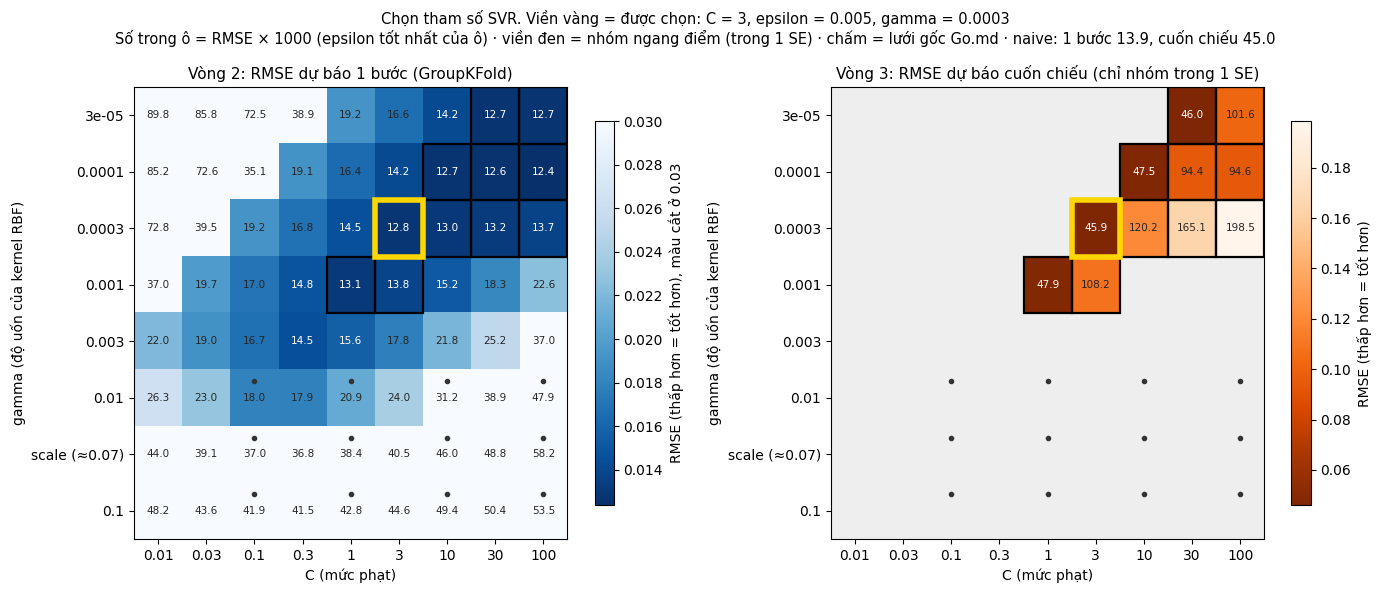

In [8]:
fig = exp.plotter.tuning_heatmap(exp.tuner)
plt.show()

## Bước 5. Train model cuối và dự báo (`SVRForecaster`, `RecursiveForecaster`)

Model cuối = cấu hình đã chọn, train lại trên **toàn bộ** dòng train.

- **E1 (1 bước):** lag là SOH **thật** của các chu kỳ trước.
- **E2 (cuốn chiếu):** đứng ở dòng `is_eval` đầu tiên (mốc 60%), mỗi giá trị vừa dự báo trở thành `soh_lag1` của bước sau. Các số đo chưa biết sau mốc (`chg_cc_time_s`, `Re_ohm`, `Rct_ohm`, `T_max_prev_C`, `log_rest_h`) được **giữ ở giá trị cuối cùng đã biết**.

**Khoảng dự báo 95% cho E1 (conformal):** lấy phần dư out-of-fold trên các pin train, q = phân vị 95% của |sai số|, khoảng = ŷ ± q. Không tính cho E2 vì sai số tăng theo số bước.

In [9]:
pred = exp.fit_predict()
print("nửa độ rộng khoảng conformal q95 = %.4f SOH" % exp.forecaster.q_)
print("tỉ lệ giá trị thật nằm trong khoảng E1: %.1f%%" % (100 * exp.forecaster.interval_coverage(pred)))
pred.head()

nửa độ rộng khoảng conformal q95 = 0.0275 SOH
tỉ lệ giá trị thật nằm trong khoảng E1: 88.7%


,model,battery_id,cycle_valid,scenario,y_true,y_pred,y_lower,y_upper
0,svr,B0007,102,E1,0.829829,0.827017,0.799518,0.854515
1,svr,B0007,103,E1,0.832620,0.832847,0.805348,0.860345
2,svr,B0007,104,E1,0.837850,0.823312,0.795813,0.850810
3,svr,B0007,105,E1,0.832759,0.828313,0.800814,0.855812
4,svr,B0007,106,E1,0.827072,0.826515,0.799017,0.854014


## Bước 6. Chấm điểm, so với naive

`evaluate()` của nhóm kiểm tra file dự báo đúng 213 dòng `is_eval` ở cả hai kịch bản, rồi tính MAE, RMSE, MAPE, R² và sai số RUL của E2 (`rul_error` > 0: cảnh báo muộn; < 0: cảnh báo sớm; `eol_pred` NaN: dự báo không bao giờ chạm SOH 0,8).

In [10]:
metrics, rul = exp.evaluate()
exp.pooled_metrics().round(4)

n     MAE    RMSE  MAPE_pct      R2
scenario model                                       
E1       naive  213  0.0119  0.0226    1.4288  0.5001
         svr    213  0.0100  0.0172    1.2000  0.7108
E2       naive  213  0.0249  0.0343    3.1271 -0.1552
         svr    213  0.0544  0.0637    6.6974 -2.9763

In [11]:
exp.per_battery_rmse().round(4)

model                 naive     svr  svr_better
scenario battery_id                            
E1       B0007       0.0037  0.0055       False
         B0034       0.0135  0.0107        True
         B0047       0.0172  0.0117        True
         B0055       0.0462  0.0347        True
E2       B0007       0.0515  0.0559       False
         B0034       0.0179  0.0817       False
         B0047       0.0199  0.0341       False
         B0055       0.0305  0.0505       False

In [12]:
rul

,model,battery_id,eol_true,eol_pred,rul_error
0,naive,B0007,126.0,NaN,NaN
1,naive,B0034,186.0,NaN,NaN
2,naive,B0055,65.0,NaN,NaN
3,svr,B0007,126.0,110.0,-16.0
4,svr,B0034,186.0,129.0,-57.0
5,svr,B0055,65.0,80.0,15.0


## Bước 7–8. Hình: SOH thật và dự báo, đường E2 tới EOL

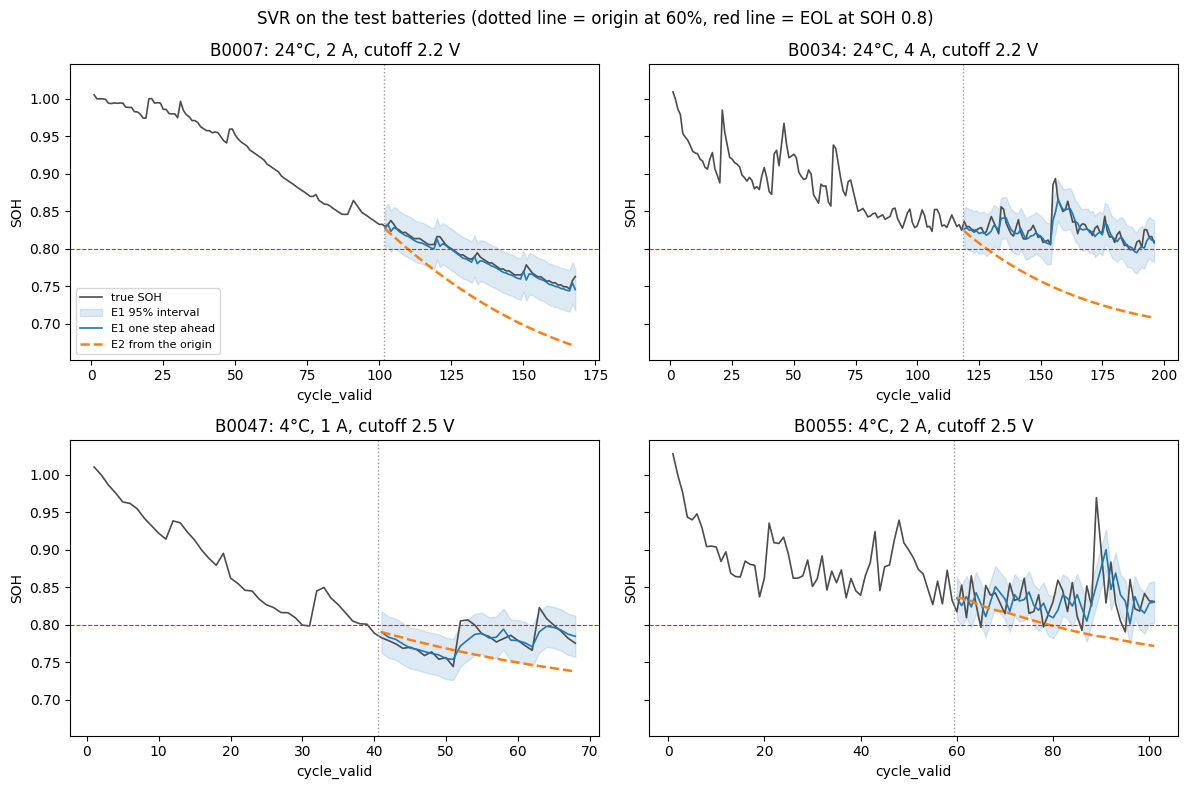

In [13]:
fig = exp.plotter.forecasts(test, pred)
plt.show()

## RQ4. Đặc trưng nào quan trọng (`ImportanceAnalyzer`)

Xáo trộn từng đặc trưng trên các dòng E1 của tập test (30 lần), đo RMSE tăng bao nhiêu. Vì 5 lag và `soh_roll5` gần như cùng thông tin, xáo riêng một cái thì model vẫn đọc được từ các cái còn lại, nên ta xáo thêm **cả nhóm lịch sử SOH** cùng lúc.

Đối chiếu với hệ số hồi quy của Quốc Đạt (WBS C6.4): hồi quy giải thích SOH theo điều kiện vận hành; bảng này cho biết đầu vào nào mang thông tin dự báo **ngoài lịch sử SOH gần đây**.

In [14]:
imp = exp.explain()
print("RMSE test (E1) khi chưa xáo trộn = %.5f" % exp.importance.base_rmse_)
imp.round(5)

RMSE test (E1) khi chưa xáo trộn = 0.01718


,feature,RMSE_increase,sd
0,[group] SOH history (lags 1-5 + roll5),0.02422,0.00126
1,soh_lag1,0.00980,0.00091
2,log_rest_h,0.00289,0.00025
3,I_level_A,0.00254,0.00038
4,soh_lag2,0.00102,0.00031
5,T_max_prev_C,0.00058,0.00021
6,soh_roll5,0.00057,0.00023
7,Re_ohm,0.00019,0.00011
8,soh_lag5,0.00009,0.00009
9,chg_cc_time_s,0.00008,0.00006


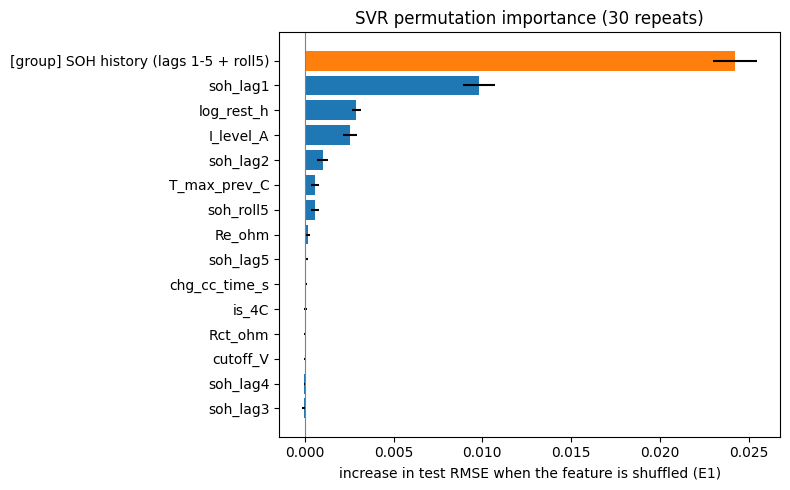

In [15]:
fig = exp.plotter.importance(imp)
plt.show()

## Lưu file dự báo

In [16]:
path = exp.save()      # lưu và kiểm tra lại bằng evaluate() của nhóm
print(f"{len(pred)} dòng -> {path.relative_to(ROOT).as_posix()}")

426 dòng -> reports/predictions/svr.csv


## Ghi chú cho báo cáo và review

- **Các quyết định cần ghi vào Work_log (phần Minh Vũ):** mở rộng lưới tham số (tham số tốt nhất nằm ở biên lưới Go.md); quy tắc 1-SE với RMSE cuốn chiếu để phân định (RMSE 1 bước phẳng theo hướng C lớn, γ nhỏ, RMSE cuốn chiếu thì không); E2 giữ các số đo ở giá trị cuối cùng đã biết; khoảng E1 bằng conformal; điền median cho 57 giá trị Re/Rct thiếu, đặt trong Pipeline.
- **Mọi con số trong báo cáo phải đọc từ bảng ở trên, không gõ tay** (README mục 9.7).
- Phải nói thẳng chỗ SVR **không** thắng naive (bảng theo pin, kịch bản E2).
- Trước khi mở Pull Request vào `main`: README quy định notebook và code bằng tiếng Anh, nên phần ghi chú tiếng Việt có thể phải dịch lại. Hỏi Khải Hưng trước.